# City as a Graph

this notebook aims to load cadastral data and interpret buildings and roads as a graph. The graph is based on the OSM map, which makes available a graph represenation with nodes and edges. </br> The nodes are successively linked with the Swiss adresses database (nearest point). Each nodes receives a EGID, the Swiss unique buliding identifier.

In [3]:
%load_ext autoreload
%autoreload 2

import osmnx
import geopandas as gpd

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [4]:
# params
src = r"../data/"

In [5]:
place_name = "Selnau"
# networkx graph of the named place
graph = osmnx.graph_from_address(place_name, dist=500)

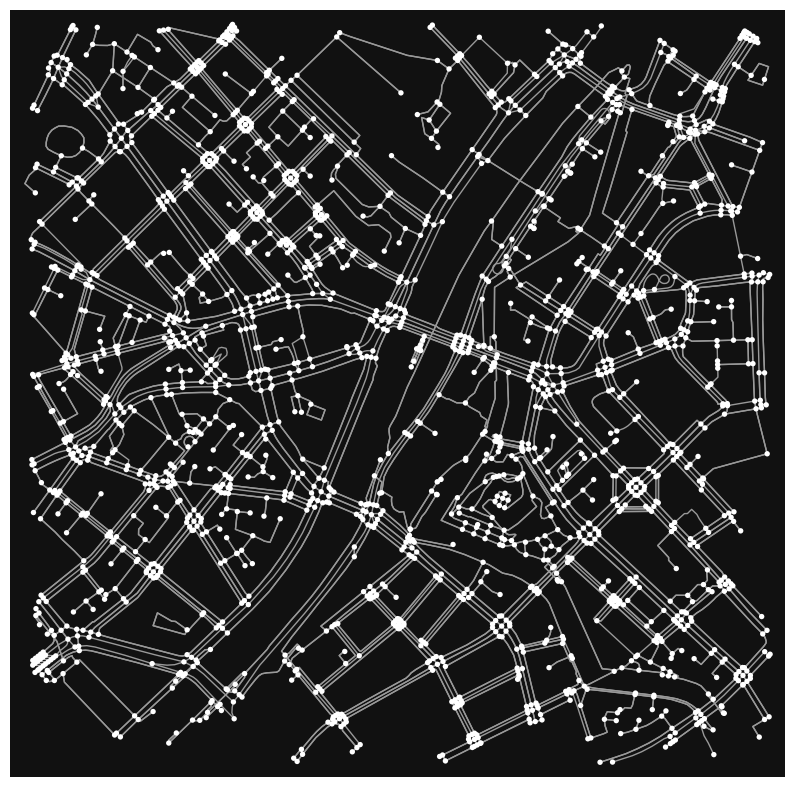

In [6]:

# Plot the graphs
osmnx.plot_graph(graph,figsize=(10,10));

In [7]:
type(graph)

networkx.classes.multidigraph.MultiDiGraph

In [8]:
nodes, edges = osmnx.graph_to_gdfs(graph)

In [9]:
nodes.head()

,y,x,street_count,junction,highway,ref,geometry
osmid,,,,,,,
469720,47.368707,8.528849,4,NaN,NaN,NaN,POINT (8.52885 47.36871)
4366192,47.370986,8.531328,6,NaN,NaN,NaN,POINT (8.53133 47.37099)
4366196,47.373851,8.533391,4,NaN,NaN,NaN,POINT (8.53339 47.37385)
26114462,47.373197,8.527950,3,yes,NaN,NaN,POINT (8.52795 47.3732)
26114482,47.376781,8.538066,4,NaN,NaN,NaN,POINT (8.53807 47.37678)


In [10]:
edges.head()

osmid   highway lanes  \
u       v           key                                                  
469720  260746808   0                        188708012  tertiary     1   
        2261078144  0    [4730411, 4730412, 188708015]   primary     3   
4366192 5257663325  0                          4572089  tertiary     4   
        1260863596  0                          4730409  tertiary     2   
        12091612856 0                       1206112447   service     2   

                        maxspeed  \
u       v           key            
469720  260746808   0         50   
        2261078144  0         50   
4366192 5257663325  0         50   
        1260863596  0         50   
        12091612856 0         50   

                                                                      name  \
u       v           key                                                      
469720  260746808   0                                    Sihlhölzlistrasse   
        2261078144  0    [Sihlhölzlibrücke, Tunnelstrasse, Manessestrasse]   
4366192 5257663325  0                                    Stauffacherbrücke   
        1260863596  0                                    Sihlhölzlistrasse   
        12091612856 0                                        Selnaustrasse   

                         oneway reversed     length  \
u       v           key                               
469720  260746808   0      True    False  23.480162   
        2261078144  0      True    False  72.690089   
4366192 5257663325  0     False    False   8.332507   
        1260863596  0      True    False  14.463347   
        12091612856 0     False    False  10.434012   

                                                                  geometry  \
u       v           key                                                      
469720  260746808   0    LINESTRING (8.52885 47.36871, 8.52883 47.36864...   
        2261078144  0    LINESTRING (8.52885 47.36871, 8.52871 47.36879...   
4366192 5257663325  0      LINESTRING (8.53133 47.37099, 8.53123 47.37102)   
        1260863596  0      LINESTRING (8.53133 47.37099, 8.53127 47.37086)   
        12091612856 0      LINESTRING (8.53133 47.37099, 8.53144 47.37093)   

                         ref bridge access width service tunnel  
u       v           key                                          
469720  260746808   0    NaN    NaN    NaN   NaN     NaN    NaN  
        2261078144  0      3    yes    NaN   NaN     NaN    NaN  
4366192 5257663325  0    NaN    NaN    NaN   NaN     NaN    NaN  
        1260863596  0    NaN    NaN    NaN   NaN     NaN    NaN  
        12091612856 0    NaN    NaN     no   NaN     NaN    NaN

In [11]:
# Rendering the 2nd node
list(graph.nodes(data=True))[1]

(4366192, {'y': 47.3709861, 'x': 8.5313283, 'street_count': 6})

In [12]:
# Rendering the 1st edge
list(graph.edges(data=True))[0]

(469720,
 260746808,
 {'osmid': 188708012,
  'highway': 'tertiary',
  'lanes': '1',
  'maxspeed': '50',
  'name': 'Sihlhölzlistrasse',
  'oneway': True,
  'reversed': False,
  'length': 23.48016201363265,
  'geometry': <LINESTRING (8.529 47.369, 8.529 47.369, 8.529 47.369, 8.529 47.369)>})

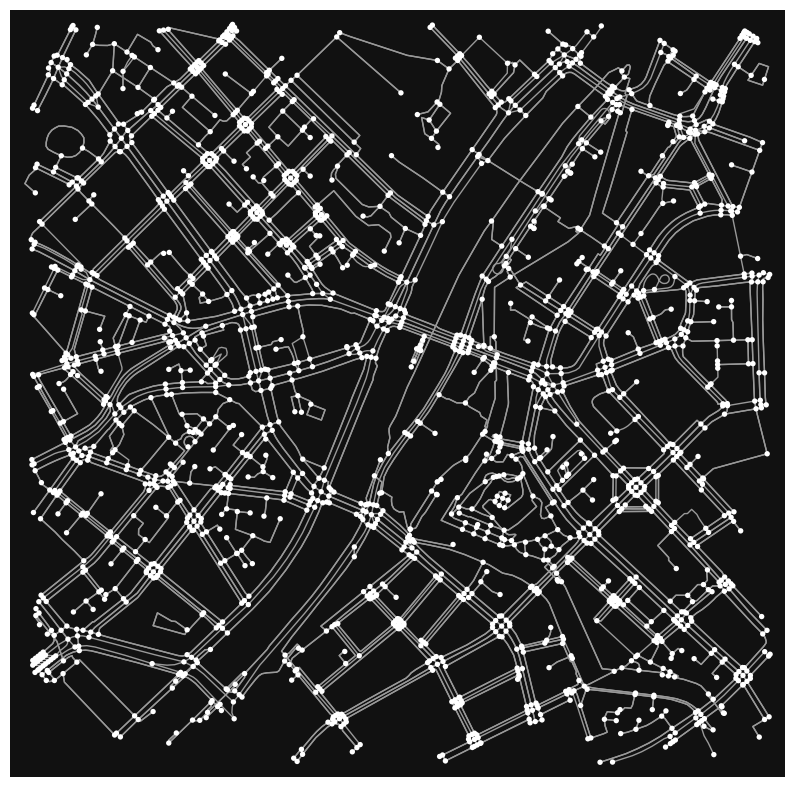

In [13]:
# creating a new graph from nodes and edges geodatabases
new_graph = osmnx.graph_from_gdfs(nodes,edges)
osmnx.plot_graph(new_graph,figsize=(10,10));

In [14]:
# Retrieving street types
print(edges['highway'].value_counts())

highway
footway                         3378
service                          896
residential                      621
tertiary                         360
[footway, steps]                 102
path                              81
cycleway                          61
steps                             38
primary                           33
pedestrian                        32
living_street                     21
[footway, service]                18
unclassified                       4
[service, path]                    4
[living_street, residential]       2
[footway, service, steps]          2
[footway, path]                    2
[path, steps]                      2
[pedestrian, service]              2
[path, residential]                2
[pedestrian, footway]              2
Name: count, dtype: int64


In [15]:
# network stats
osmnx.basic_stats(graph)

{'n': 2015,
 'm': 5663,
 'k_avg': 5.620843672456576,
 'edge_length_total': 130803.02299042011,
 'edge_length_avg': 23.09783206611692,
 'streets_per_node_avg': 3.189578163771712,
 'streets_per_node_counts': {0: 0,
  1: 173,
  2: 15,
  3: 1123,
  4: 675,
  5: 19,
  6: 10},
 'streets_per_node_proportions': {0: 0.0,
  1: 0.0858560794044665,
  2: 0.007444168734491315,
  3: 0.5573200992555831,
  4: 0.3349875930521092,
  5: 0.009429280397022333,
  6: 0.004962779156327543},
 'intersection_count': 1842,
 'street_length_total': 72407.01338323383,
 'street_segment_count': 3120,
 'street_length_avg': 23.20737608436982,
 'circuity_avg': 1.0314947044470137,
 'self_loop_proportion': 0.000641025641025641}

## Loading Building footprints and Adresses from OSM
this apporoach doesn't work, since the EGID (building ID) is not available on this database

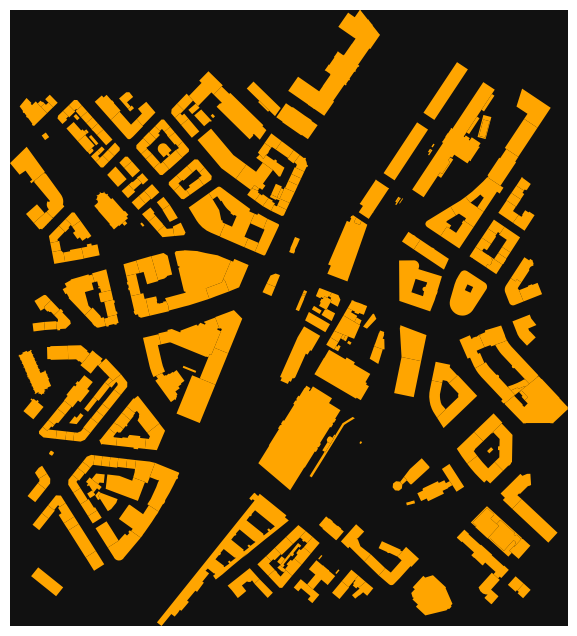

(<Figure size 800x800 with 1 Axes>, <Axes: >)

In [16]:
# Retrieve the building footprint, project it to match our previous graph, and plot it.
buildings = osmnx.features.features_from_address(place_name, tags={'building':True}, dist=300)
# buildings = buildings.to_crs(edges.crs)
osmnx.plot_footprints(buildings)

In [17]:
buildings

geometry  \
element  id                                                              
relation 1206537     POLYGON ((8.53519 47.37316, 8.53521 47.37315, ...   
         1363358     POLYGON ((8.53138 47.37072, 8.53135 47.37073, ...   
         1701522     POLYGON ((8.53402 47.37341, 8.53403 47.37341, ...   
         17617717    POLYGON ((8.5353 47.37502, 8.5352 47.37477, 8....   
         17649189    POLYGON ((8.53214 47.37299, 8.53215 47.37299, ...   
...                                                                ...   
way      1287639369  POLYGON ((8.53376 47.37412, 8.53378 47.37411, ...   
         1287639370  POLYGON ((8.53378 47.37411, 8.5338 47.37411, 8...   
         1287656605  POLYGON ((8.53219 47.37304, 8.53222 47.37303, ...   
         1305355239  POLYGON ((8.53385 47.37098, 8.5339 47.37094, 8...   
         1311187425  POLYGON ((8.5279 47.37394, 8.52778 47.37404, 8...   

                    addr:city addr:country addr:housenumber addr:postcode  \
element  id                                                                 
relation 1206537          NaN          NaN              NaN           NaN   
         1363358          NaN          NaN              NaN           NaN   
         1701522          NaN          NaN              NaN           NaN   
         17617717         NaN          NaN              NaN           NaN   
         17649189         NaN          NaN              NaN           NaN   
...                       ...          ...              ...           ...   
way      1287639369       NaN          NaN              NaN           NaN   
         1287639370       NaN          NaN              NaN           NaN   
         1287656605       NaN          NaN              NaN           NaN   
         1305355239       NaN          NaN              46a           NaN   
         1311187425    Zürich           CH               12          8004   

                        addr:street    building          description  \
element  id                                                            
relation 1206537                NaN  commercial                  NaN   
         1363358                NaN  apartments  Wohnsiedlung Selnau   
         1701522                NaN  apartments                  NaN   
         17617717               NaN        roof                  NaN   
         17649189               NaN        roof                  NaN   
...                             ...         ...                  ...   
way      1287639369             NaN     service                  NaN   
         1287639370             NaN        roof                  NaN   
         1287656605             NaN     service                  NaN   
         1305355239  Pelikanstrasse         yes                  NaN   
         1311187425  Kanzleistrasse         yes                  NaN   

                          name                                       owner  \
element  id                                                                  
relation 1206537     Schmidhof                                         NaN   
         1363358           NaN  Stadt Zürich, FD, Liegenschaftenverwaltung   
         1701522           NaN                          AXA Anlagestiftung   
         17617717          NaN                                         NaN   
         17649189          NaN                                         NaN   
...                        ...                                         ...   
way      1287639369        NaN                                         NaN   
         1287639370        NaN                                         NaN   
         1287656605        NaN                                         NaN   
         1305355239        NaN                                         NaN   
         1311187425        NaN                                         NaN   

                     ... layer old_name construction building:flats fixme  \
element  id          ...                                            

<Axes: >

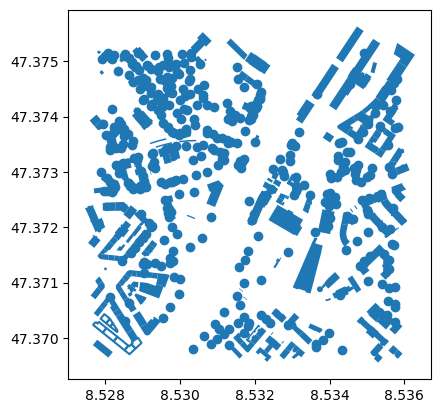

In [18]:
# Retrieve the building footprint, project it to match our previous graph, and plot it.
addresses = osmnx.features.features_from_address(place_name, tags={'addr:housenumber':True}, dist=300)
# buildings = buildings.to_crs(edges.crs)
addresses.plot()

## Loading Swiss adresses geodatabase 

loading the Swiss adresses database

In [20]:
agv = gpd.read_file(src + 'amtliches-gebaeudeadressverzeichnis_ch_2056/amtliches-gebaeudeadressverzeichnis_ch_2056.gdb', 
                    encoding="utf8")

C:\Users\suli\AppData\Local\anaconda3\Lib\site-packages\pyogrio\geopandas.py:265: UserWarning: More than one layer found in 'amtliches-gebaeudeadressverzeichnis_ch_2056.gdb': 'PURE_ADR' (default), 'PURE_STR', 'PURE_STN', 'PURE_STZ', 'PURE_ZIP', 'PURE_LIN', 'PURE_PLY'. Specify layer parameter to avoid this warning.
  result = read_func(


In [21]:
agv.head()

,ADR_EGAID,STZ_ID,COM_FOSNR,COM_NAME,COM_CANTON,BDG_EGID,ADR_EDID,ADR_NUMBER,BDG_CATEGORY,BDG_NAME,ADR_STATUS,ADR_OFFICIAL,ADR_MODIFIED,geometry
0,101383493.0,292879,2862,Tecknau,BL,245000582.0,0,21,2,None,1,1,2024-11-15 00:00:00+00:00,POINT (2633975.95 1255061.706)
1,100314548.0,316997,2763,Arlesheim,BL,394836.0,0,7,2,None,1,1,2024-11-15 00:00:00+00:00,POINT (2613439.954 1260120.766)
2,101530096.0,192947,2763,Arlesheim,BL,245042640.0,0,33,5,None,1,1,2024-11-15 00:00:00+00:00,POINT (2614015.462 1259798.452)
3,100353307.0,193274,2771,Oberwil (BL),BL,409584.0,0,42,2,None,1,1,2024-11-15 00:00:00+00:00,POINT (2609302.619 1262471.997)
4,100351325.0,193701,2825,Füllinsdorf,BL,418098.0,0,15,2,None,1,1,2024-11-15 00:00:00+00:00,POINT (2622218.336 1261888.793)


selecting only the adresses within the municipality of Zurich

In [22]:
geobrd = gpd.read_file(src + "swissBOUNDARIES3D_1_5_LV95_LN02.gdb/",  driver='FileGDB', layer = "TLM_HOHEITSGEBIET")
geozhc = geobrd.loc[geobrd.BFS_NUMMER == 261] # selecting Zuerich geometry to simplify the experiment

C:\Users\suli\AppData\Local\anaconda3\Lib\site-packages\pyogrio\raw.py:198: RuntimeWarning: driver OpenFileGDB does not support open option DRIVER
  return ogr_read(


In [23]:
agvzh = gpd.sjoin(agv, geozhc, how='inner', predicate='within')
agvzh = agvzh.drop(['index_right'], axis=1)

C:\Users\suli\AppData\Local\Temp\ipykernel_22656\4063965763.py:1: UserWarning: CRS mismatch between the CRS of left geometries and the CRS of right geometries.
Use `to_crs()` to reproject one of the input geometries to match the CRS of the other.

Left CRS: EPSG:2056
Right CRS: COMPD_CS["CH1903+ / LV95 + LN02 height",PROJCS["CH ...

  agvzh = gpd.sjoin(agv, geozhc, how='inner', predicate='within')


In [24]:
agvzh = agvzh.to_crs(4326) # keeping the graph database crs, otherwise the graph is messed up

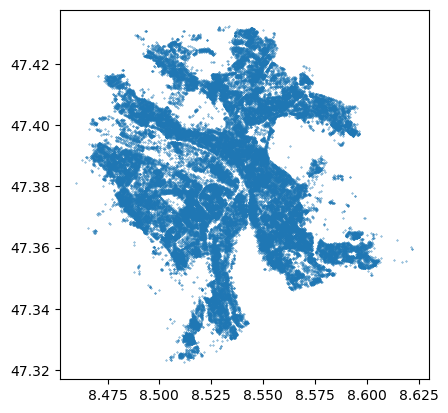

In [25]:
agvzh.plot(markersize = 0.1);

## Finding the closest node to the address point

In [26]:
res = gpd.sjoin_nearest(nodes, agvzh, how='left', max_distance=50, distance_col='dist')

C:\Users\suli\AppData\Local\anaconda3\Lib\site-packages\geopandas\array.py:403: UserWarning: Geometry is in a geographic CRS. Results from 'sjoin_nearest' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  warnings.warn(


In [27]:
res.shape[0] - nodes.shape[0] # all nodes received and address and an EGID

0

In [28]:
res.head()

,y,x,street_count,junction,highway,ref,geometry,index_right,ADR_EGAID,STZ_ID,...,BEZIRKSNUMMER,KANTONSNUMMER,NAME,GEM_FLAECHE,SEE_FLAECHE,ICC,SHN,EINWOHNERZAHL,HIST_NR,dist
osmid,,,,,,,,,,,,,,,,,,,,,
469720,47.368707,8.528849,4,NaN,NaN,NaN,POINT (8.52885 47.36871),2863220,101739770.0,169756,...,112.0,1.0,Zürich,9188.0,395.0,CH,CH01120261,423193,13688.0,0.000479
4366192,47.370986,8.531328,6,NaN,NaN,NaN,POINT (8.53133 47.37099),2898619,103286887.0,169713,...,112.0,1.0,Zürich,9188.0,395.0,CH,CH01120261,423193,13688.0,0.000335
4366196,47.373851,8.533391,4,NaN,NaN,NaN,POINT (8.53339 47.37385),1899799,101732759.0,169679,...,112.0,1.0,Zürich,9188.0,395.0,CH,CH01120261,423193,13688.0,0.000242
26114462,47.373197,8.527950,3,yes,NaN,NaN,POINT (8.52795 47.3732),2164685,101146507.0,259159,...,112.0,1.0,Zürich,9188.0,395.0,CH,CH01120261,423193,13688.0,0.000271
26114482,47.376781,8.538066,4,NaN,NaN,NaN,POINT (8.53807 47.37678),2586963,101732774.0,169689,...,112.0,1.0,Zürich,9188.0,395.0,CH,CH01120261,423193,13688.0,0.000197


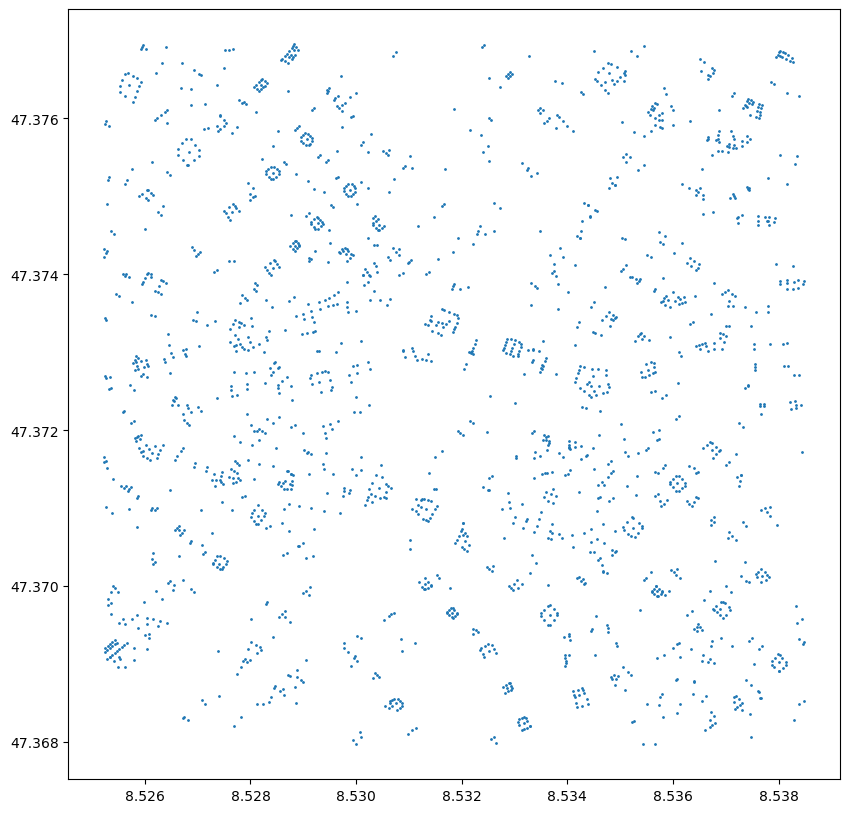

In [29]:
res.plot(markersize=1, figsize=(10,10));

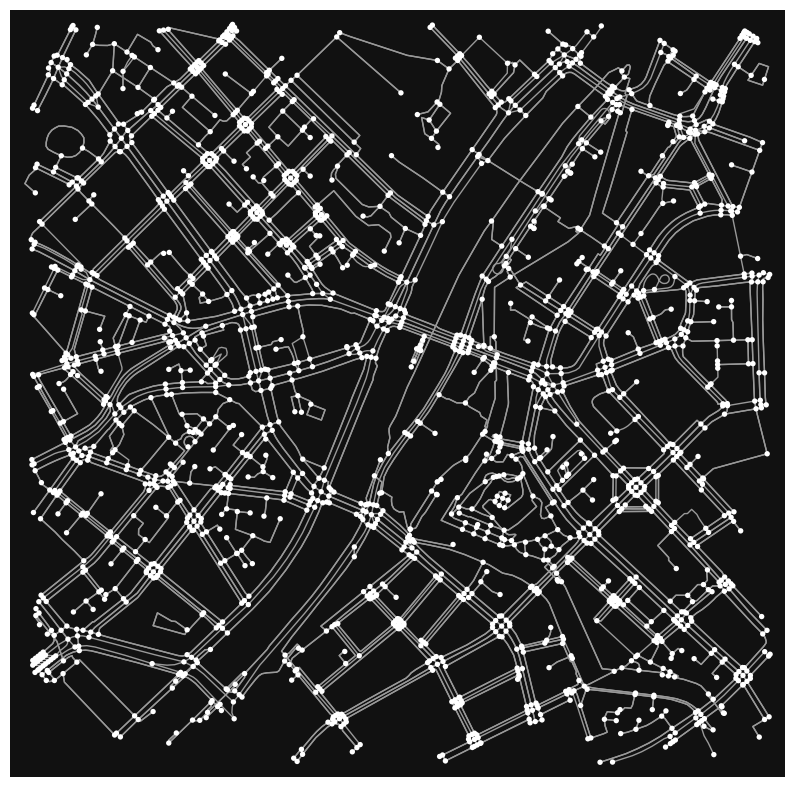

In [30]:
new_graph = osmnx.graph_from_gdfs(res, edges)
osmnx.plot_graph(new_graph,figsize=(10,10));